In [48]:
import os
from dotenv import load_dotenv
load_dotenv("../.env") 

## CONFIG
LLM_BASE_URL=os.getenv("LLM_BASE_URL")
LLM_API_KEY=os.getenv("LLM_API_KEY")
LLM_MODEL_NAME=os.getenv("LLM_MODEL_NAME")

In [49]:
from langchain.chat_models import init_chat_model

In [50]:
llm = init_chat_model(
    model=LLM_MODEL_NAME,
    model_provider="openai",
    base_url=LLM_BASE_URL,
    api_key=LLM_API_KEY,
)

print(llm.invoke("Hi").content)



Hello! How can I help you today?


## LengGref

## Hello World kind of thing

In [ ]:
from langgraph.graph import StateGraph, MessagesState, START, END


def the_llm(state: MessagesState):
    
    user_messsage = str(state["messages"][0].content)
    ai_message = llm.invoke(user_messsage).content
    
    return {
        "messages": [{
            "role": "ai",
            "content": ai_message
        }]
    }

In [26]:
graph = StateGraph(MessagesState)
graph.add_node(the_llm)
graph.add_edge(START, "the_llm")
graph.add_edge("the_llm", END)
graph = graph.compile()

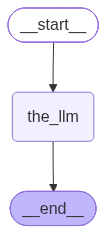

In [28]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [29]:
answer = graph.invoke({
    "messages": [{
        "role": "user",
        "content": "hi!"
    }]
})

print(answer["messages"][1].content)



Hello! How can I help you today?


## The Quickstart hiks

### Define tools and model

In [30]:
from langchain.tools import tool
from langchain.chat_models import init_chat_model

In [ ]:
model = init_chat_model(
    model=LLM_MODEL_NAME,
    model_provider="openai",
    base_url=LLM_BASE_URL,
    api_key=LLM_API_KEY,
    temperature=0,
)

In [ ]:
# tool definition

@tool
def multiply(a: int, b: int):
    """Multiply `a` and `b`.
    
    Args:
        a: First int
        b: Second int2
    """
    return a * b

@tool
def add(a: int, b: int):
    """Adds `a` and `b`.
    
    Args:
        a: First int
        b: Second int
    """
    return a + b

@tool
def divide(a: int, b: int):
    """Divide `a` and `b`.
    
    Args:
        a: First int
        b: Second int
    """
    return a / b

# Augment the LLM with tools
tools = [add, multiply, divide]
tools_by_name = {tool.name: tool for tool in tools}
model_with_tools = model.bind_tools(tools)

### Define State

In [33]:
from langchain.messages import AnyMessage
from typing_extensions import TypedDict, Annotated
import operator

In [34]:
class MessageState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]
    llm_calls: int

### Define model node

In [35]:
from langchain.messages import SystemMessage

In [36]:
def llm_call(state: dict):
    """LLM decides whether to call a tool or not"""
    
    return {
        "messages": [
            model_with_tools.invoke(
                [
                    SystemMessage(
                        content="You are a helpful assistant tasked with performing arithmetic on a set of inputs."
                    )
                ]
                + state["messages"]
            )
        ],
        "llm_calls": state.get("llm_calls", 0) + 1
    }

### Define tool node

In [37]:
from langchain.messages import ToolMessage

In [38]:
def tool_node(state: dict):
    """Performs the tool call"""
    
    result = []
    for tool_call in state["messages"][-1].tool_calls:
        tool = tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])
        result.append(
            ToolMessage(content=observation, tool_call_id=tool_call["id"])
        )
    
    return {"messages": result}

### Define end logic

In [39]:
from typing import Literal
from langgraph.graph import StateGraph, START, END

In [40]:
def should_continue(state: MessageState) -> Literal["tool_node", END]:
    """Decide if we should continue the loop or stop based upon whether the LLM made a tool call"""
    
    messages = state["messages"]
    last_message = messages[-1]
    
    # if the LLM makes a tool call, then perform an action
    if last_message.tool_calls:
        return "tool_node"
    
    # Otherwise, we stop (reply to the user)
    return END

### Build and compile the agent

In [41]:
# Build workflow
agent_builder = StateGraph(MessageState)

# Add nodes
agent_builder.add_node("llm_call", llm_call),
agent_builder.add_node("tool_node", tool_node)

# Add edges to connect nodes
agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges(
    "llm_call",
    should_continue,
    ["tool_node", END]
)
agent_builder.add_edge("tool_node", "llm_call")

# Compile the agent
agent = agent_builder.compile()

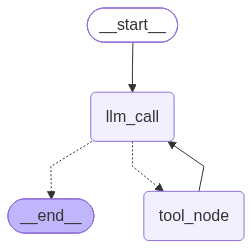

In [42]:
# Show the agent
from IPython.display import Image, display
display(Image(agent.get_graph(xray=True).draw_mermaid_png()))

### Invoke

In [43]:
from langchain.messages import HumanMessage

In [21]:
# Invoke
messages = [HumanMessage(content="Add 3 and 4.")]
messages = agent.invoke({"messages": messages})

for m in messages["messages"]:
    m.pretty_print()

================================ Human Message =================================

Add 3 and 4.
================================== Ai Message ==================================
Tool Calls:
  add (call_function_akv8l8r5vlqw_1)
 Call ID: call_function_akv8l8r5vlqw_1
  Args:
    a: 3
    b: 4
================================= Tool Message =================================

7
================================== Ai Message ==================================



3 + 4 = 7


## Integrate with QDRANT (RAGGGGG)